# Clustering in Nigerian music

Import dependencies (seaborn is data visualization library) and data.

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("nigerian-songs.csv")

Look into the data

In [9]:
df.head()

,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
0,Sparky,Mandy & The Jungle,Cruel Santino,alternative r&b,2019,144000,48,0.666,0.8510,0.420,0.534000,0.1100,-6.699,0.0829,133.015,5
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
2,LITT!,LITT!,AYLØ,indie r&b,2018,207758,40,0.836,0.2720,0.564,0.000537,0.1100,-7.127,0.0424,130.005,4
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4


In [10]:
df['artist_top_genre']

,artist_top_genre
0,alternative r&b
1,afropop
2,indie r&b
3,nigerian pop
4,afropop
...,...
525,afro dancehall
526,afro dancehall
527,afro dancehall
528,afro dancehall


Let's focus on three genres and look at their amount in our data.

Text(0.5, 1.0, 'Top genres')

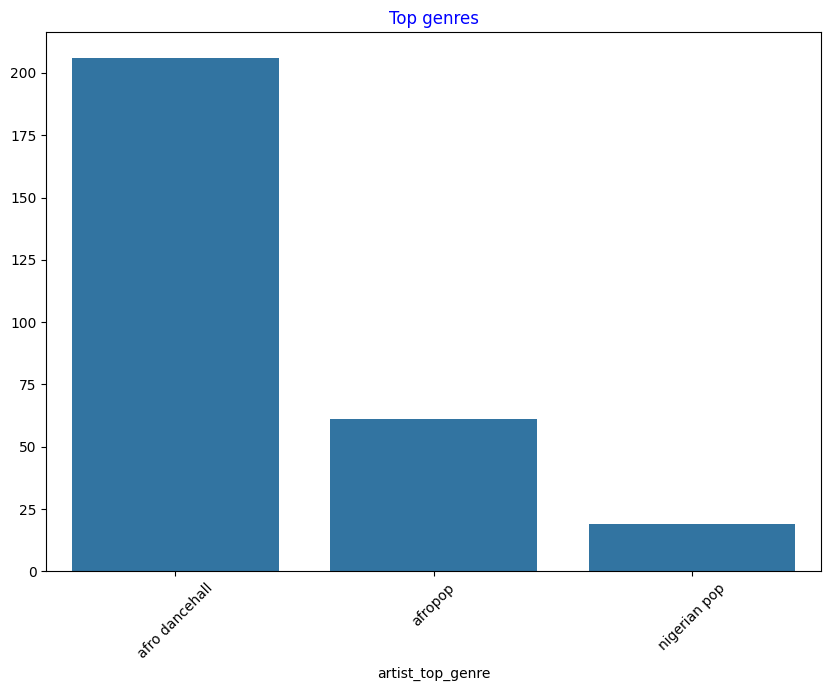

In [11]:
df = df[(df['artist_top_genre'] == 'afro dancehall') | (df['artist_top_genre'] == 'afropop') | (df['artist_top_genre'] == 'nigerian pop')]
df = df[(df['popularity'] > 0)]
top = df['artist_top_genre'].value_counts()
plt.figure(figsize=(10,7))
sns.barplot(x=top.index,y=top.values)
plt.xticks(rotation=45)
plt.title('Top genres',color = 'blue')

In [12]:
df.head()

,name,album,artist,artist_top_genre,release_date,length,popularity,danceability,acousticness,energy,instrumentalness,liveness,loudness,speechiness,tempo,time_signature
1,shuga rush,EVERYTHING YOU HEARD IS TRUE,Odunsi (The Engine),afropop,2020,89488,30,0.710,0.0822,0.683,0.000169,0.1010,-5.640,0.3600,129.993,3
3,Confident / Feeling Cool,Enjoy Your Life,Lady Donli,nigerian pop,2019,175135,14,0.894,0.7980,0.611,0.000187,0.0964,-4.961,0.1130,111.087,4
4,wanted you,rare.,Odunsi (The Engine),afropop,2018,152049,25,0.702,0.1160,0.833,0.910000,0.3480,-6.044,0.0447,105.115,4
5,Kasala,Pioneers,DRB Lasgidi,nigerian pop,2020,184800,26,0.803,0.1270,0.525,0.000007,0.1290,-10.034,0.1970,100.103,4
6,Pull Up,Everything Pretty,prettyboydo,nigerian pop,2018,202648,29,0.818,0.4520,0.587,0.004490,0.5900,-9.840,0.1990,95.842,4


How clean is the data? Let's check the outliers using box plots. Ultimately, we will focus on columns that have fewer outliers, but alternatively the data can be cleansed of them. Boxplots show the variety of data and will help you choose the columns to use in your clustering experiment. An important thing is that box plots, contrary to appearances, DO NOT show variance.

<Axes: xlabel='release_date'>

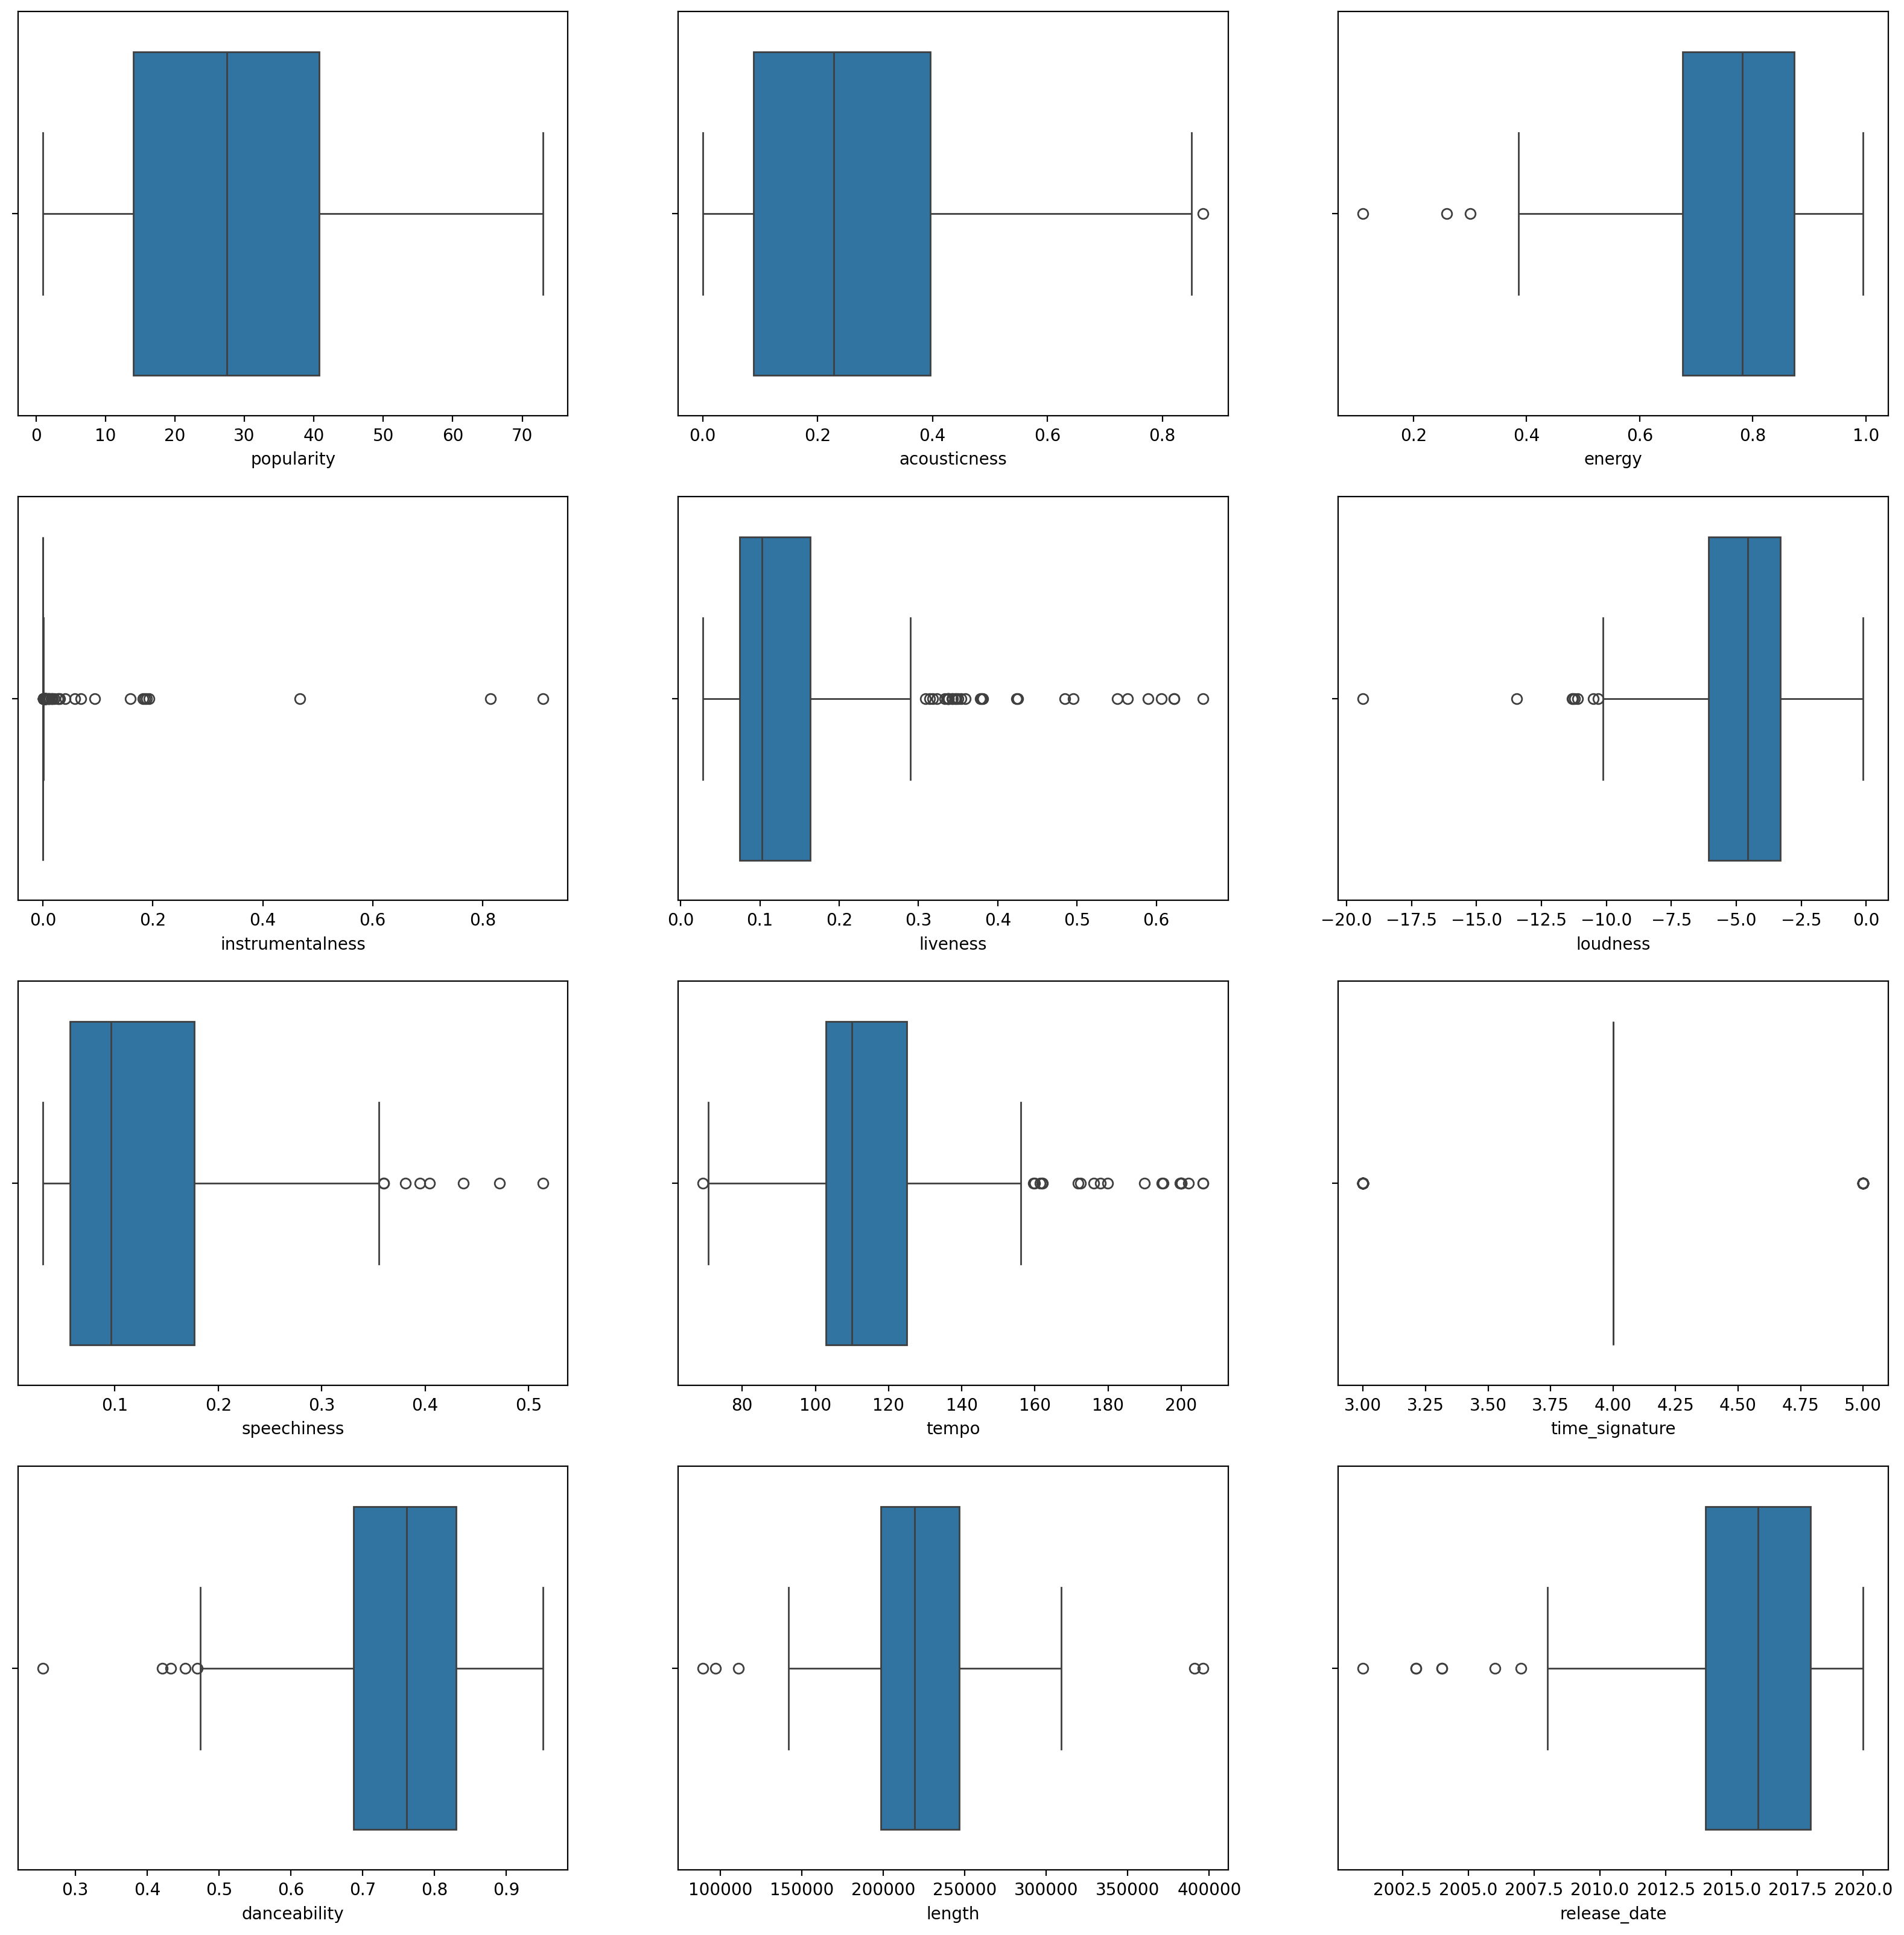

In [13]:
plt.figure(figsize=(20,20), dpi=200)

plt.subplot(4,3,1)
sns.boxplot(x = 'popularity', data = df)

plt.subplot(4,3,2)
sns.boxplot(x = 'acousticness', data = df)

plt.subplot(4,3,3)
sns.boxplot(x = 'energy', data = df)

plt.subplot(4,3,4)
sns.boxplot(x = 'instrumentalness', data = df)

plt.subplot(4,3,5)
sns.boxplot(x = 'liveness', data = df)

plt.subplot(4,3,6)
sns.boxplot(x = 'loudness', data = df)

plt.subplot(4,3,7)
sns.boxplot(x = 'speechiness', data = df)

plt.subplot(4,3,8)
sns.boxplot(x = 'tempo', data = df)

plt.subplot(4,3,9)
sns.boxplot(x = 'time_signature', data = df)

plt.subplot(4,3,10)
sns.boxplot(x = 'danceability', data = df)

plt.subplot(4,3,11)
sns.boxplot(x = 'length', data = df)

plt.subplot(4,3,12)
sns.boxplot(x = 'release_date', data = df)

Select several columns with as few outliers as possible, one of the possibilities is proposed. We must remember to include the artist_top_genre column to retain the information that determines the division into clusters.

In [14]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
X = df.loc[:, ('artist_top_genre','popularity','danceability','acousticness','loudness','energy')]
y = df['artist_top_genre']
X['artist_top_genre'] = le.fit_transform(X['artist_top_genre'])
y = le.transform(y)

In [15]:
X

,artist_top_genre,popularity,danceability,acousticness,loudness,energy
1,1,30,0.710,0.0822,-5.640,0.683
3,2,14,0.894,0.7980,-4.961,0.611
4,1,25,0.702,0.1160,-6.044,0.833
5,2,26,0.803,0.1270,-10.034,0.525
6,2,29,0.818,0.4520,-9.840,0.587
...,...,...,...,...,...,...
514,0,20,0.838,0.0358,-3.723,0.931
515,0,14,0.786,0.1950,-4.232,0.806
519,1,2,0.879,0.2240,-4.602,0.916
522,0,26,0.863,0.0366,-3.130,0.896


We will use the k-means algorithm for clustering. Its feature is that we must provide it directly as input how many clusters we expect at the output. Let's check on a different number of clusters what it will look like and collect metrics showing how well it was done, helping to select the optimal number of clusters - first of all, the `WCSS (Within-Cluster Sum of Square)' value, i.e. the sum of the squares of the distance of the samples from the cluster center.

**Task 1.** Look at the documentation of the KMeans algorithm in scikit-learn and enter the expression in the appropriate place that will collect the WCSS values

In [16]:
from sklearn.cluster import KMeans
y_cluster_kmeans = {}
kmeans_models = {}
wcss = []
for i in range(2, 11): # for the number of clusters from 2 to 10
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 0) # create an instance of the model
    kmeans.fit(X) # train the model
    print(f"{i} clusters generated")
    wcss.append(kmeans.fit_transform(X)) # collect metrics - FILL THE GAP
    kmeans_models[i] = kmeans
    y_cluster_kmeans[i] = kmeans.predict(X) # we make a prediction, i.e. we give it a cluster number for each element in the data
y_cluster_kmeans

2 clusters generated
3 clusters generated
4 clusters generated
5 clusters generated
6 clusters generated
7 clusters generated
8 clusters generated
9 clusters generated
10 clusters generated


{2: array([1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1,
        1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1,
        0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
        0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1,
        0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
        0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
        1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
        0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1,
        1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1,
        0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,
        0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       dtype=int32),
 3: array([2,

These numbers don't tell us much, so let's determine the `silhouette` factor that will assess how the data is grouped. It calculates the average distances within clusters and to their nearest neighbors. It therefore has following formula: $$ silhouette(X)= \frac{(b-a)}{max(a,b)} $$
where `a` is an average distance between each sample and the rest of the samples in own cluster, and `b` is an average distance between each sample and all samples in the nearest non-own cluster. The optimal value is 1.

**Task 2.** Let's manually implement a function that will allow us to determine the value of the `silhouette` coefficient for the clustering performed. For this we will need the kmeans.cluster_centers_ attribute, i.e. the coordinates of the cluster centers. So one by one:

    - we define the distance between points
    - for each point (data record):
            - we calculate its distance from the centers of all clusters and write down these distances
            - we check the nearest non-own cluster and measure the distance from its center (b)
            - we check our own cluster and measure the distance from its center (a)
    - given a and b, we calculate the silhouette value

**Knowing the algorithm, complete the code below in the places marked ... with the following fragments:**

    1. distance_intra['sum'] += distance(input_data.iloc[i], input_data.iloc[j])
       distance_intra['counter'] += 1
    2. 7 cntrs = kmeans.cluster_centers_
    3. 7 score = (mean_distance_extra-mean_distance_intra) / max(mean_distance_extra, mean_distance_intra)
    4. 7 distance_extra['sum'] += distance(input_data.iloc[i], input_data.iloc[j])
       distance_extra['counter'] += 1
    5. 7 return m.sqrt(sum([pow(point1[k]-point2[k], 2) for k in range(len(point1)-1)]))

In [17]:
import numpy as np
import math as m
from sklearn import metrics

def distance(point1, point2):
    return m.sqrt(sum([pow(point1[k]-point2[k], 2) for k in range(len(point1)-1)]))

def silhouette(input_data, results, kmeans):
    cntrs = kmeans.cluster_centers_

    distance_intra = {'sum':0, 'counter': 0}
    distance_extra = {'sum':0, 'counter': 0}

    for i in range(len(input_data)):
        cluster_distances = [distance(input_data.iloc[i], c) for c in cntrs]
        cluster_distances[results[i]] = max(cluster_distances) + 10

        for j in [k for k in range(len(results)) if results[k] == np.argmin(cluster_distances)]:
            distance_extra['sum'] += distance(input_data.iloc[i], input_data.iloc[j])
            distance_extra['counter'] += 1

        for j in [k for k in range(len(results)) if results[k] == results[i]]:
            distance_intra['sum'] += distance(input_data.iloc[i], input_data.iloc[j])
            distance_intra['counter'] += 1

    mean_distance_extra = distance_extra['sum'] / distance_extra['counter']
    mean_distance_intra = distance_intra['sum'] / distance_intra['counter']

    score = (mean_distance_extra-mean_distance_intra) / max(mean_distance_extra, mean_distance_intra)

    return score

Call our function:

In [18]:
for i in range(2,11):
    print(f"Calculated silhouette value for {i} clusters: {silhouette(X, y_cluster_kmeans[i], kmeans_models[i])}")

/tmp/ipykernel_1113/3556315584.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return m.sqrt(sum([pow(point1[k]-point2[k], 2) for k in range(len(point1)-1)]))


Calculated silhouette value for 2 clusters: 0.607614449553938
Calculated silhouette value for 3 clusters: 0.5974935976776913
Calculated silhouette value for 4 clusters: 0.5582729832288614
Calculated silhouette value for 5 clusters: 0.5227154440086306
Calculated silhouette value for 6 clusters: 0.5098235508337157
Calculated silhouette value for 7 clusters: 0.485422068358538
Calculated silhouette value for 8 clusters: 0.47426121029656615
Calculated silhouette value for 9 clusters: 0.4487017617308079
Calculated silhouette value for 10 clusters: 0.4419274390713047


Now let's use the built-in function in scikit-learn to check whether the above result is (more or less) correct.

In [19]:
from sklearn import metrics
for i in range(2,11):
    score = metrics.silhouette_score(X, y_cluster_kmeans[i])
    print(f"Calculated silhouette value for {i} clusters: {score}")

Calculated silhouette value for 2 clusters: 0.5628313330897252
Calculated silhouette value for 3 clusters: 0.5466747351275563
Calculated silhouette value for 4 clusters: 0.5056654827553877
Calculated silhouette value for 5 clusters: 0.4792978404425128
Calculated silhouette value for 6 clusters: 0.46264065247959124
Calculated silhouette value for 7 clusters: 0.43149674573001273
Calculated silhouette value for 8 clusters: 0.41285100970578703
Calculated silhouette value for 9 clusters: 0.3738401882732871
Calculated silhouette value for 10 clusters: 0.36565507420860915


Now that we have the metric values, let's choose the number of clusters that seems most appropriate. We can help ourselves with the simplest (and most "by feel") selection technique, the Elbow Method, which basing on the occurrence of the most dynamic bend in the graph of  **WCSS<->clusters number dependency**, selects the optimal number of them.

**Task 3.** Illustrate this dependency on a plot

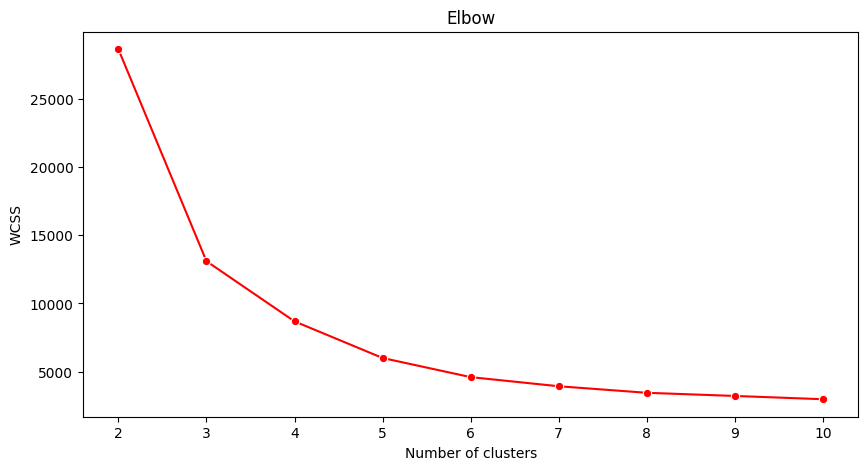

In [20]:
wcss_values = [kmeans_models[i].inertia_ for i in range(2, 11)]

plt.figure(figsize=(10,5))
sns.lineplot(x=range(2, 11), y=wcss_values, marker='o', color='red')
plt.title('Elbow')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

**Task 4.** Basing on the collected data, select the number of clusters, train the algorithm and make predictions - enter the appropriate lines in the places ...

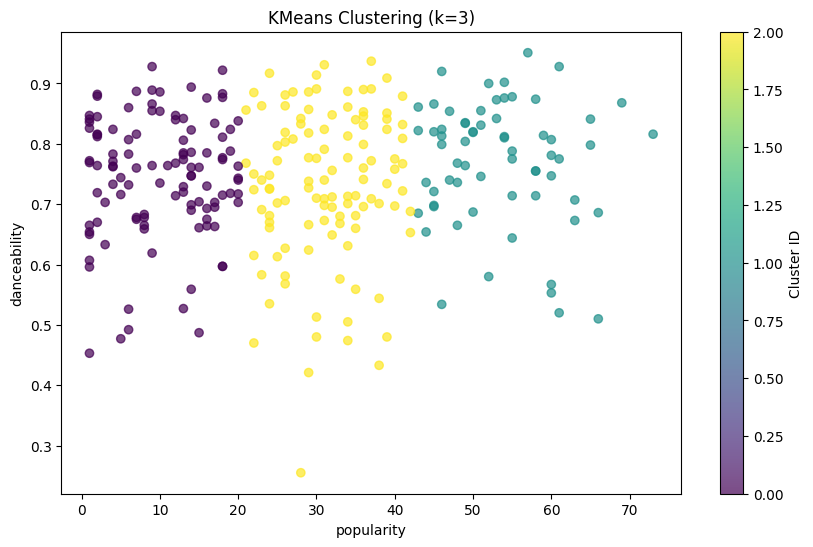

In [21]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=0)

labels = kmeans.fit_predict(X)

plt.figure(figsize=(10, 6))
plt.scatter(df['popularity'], df['danceability'], c=labels, cmap='viridis', alpha=0.7)
plt.xlabel('popularity')
plt.ylabel('danceability')
plt.title('KMeans Clustering (k=3)')
plt.colorbar(label='Cluster ID')
plt.show()

Let's check the actual accuracy of clustering, i.e. compare the classes assigned by our model to real classes.

In [22]:
labels = kmeans.labels_
correct_labels = sum(y == labels)
print("Result: %d out of %d samples were correctly labeled." % (correct_labels, y.size))
print('Accuracy score: {0:0.2f}'. format(correct_labels/float(y.size)))

Result: 111 out of 286 samples were correctly labeled.
Accuracy score: 0.39


**Task 5.** In exactly the same way as we trained the KMeans model (last cell above the graph), using the scikit-learn library fit several differently configured models of DBSCAN and AffinityPropagation algorithms (which select the number of clusters themselves) and similarly illustrate how they clustered the data.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, AffinityPropagation
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler

# Both algorithms are distance-based, so use the same standardized data for every model.
X_scaled = StandardScaler().fit_transform(X)

# DBSCAN determines the number of clusters from eps and min_samples.
dbscan_configs = [
    {"eps": 0.45, "min_samples": 4},
    {"eps": 0.70, "min_samples": 5},
    {"eps": 1.00, "min_samples": 8},
]
dbscan_models = {}
dbscan_labels = {}

for config in dbscan_configs:
    name = f"eps={config['eps']}, min_samples={config['min_samples']}"
    model = DBSCAN(**config)
    labels = model.fit_predict(X_scaled)
    dbscan_models[name] = model
    dbscan_labels[name] = labels

# AffinityPropagation also selects its own cluster count. Preference controls how
# readily observations become exemplars; using similarity quantiles gives three
# data-dependent configurations without supplying n_clusters.
similarities = -pairwise_distances(X_scaled, metric="sqeuclidean")
preference_quantiles = [0.25, 0.50, 0.75]
damping_values = [0.70, 0.85, 0.95]
affinity_models = {}
affinity_labels = {}

for quantile, damping in zip(preference_quantiles, damping_values):
    preference = np.quantile(similarities, quantile)
    name = f"damping={damping}, preference=q{int(quantile * 100)}"
    model = AffinityPropagation(
        damping=damping,
        preference=preference,
        max_iter=500,
        convergence_iter=30,
        random_state=0,
    )
    labels = model.fit_predict(X_scaled)
    affinity_models[name] = model
    affinity_labels[name] = labels

# Summarize and visualize the assignments in the same two dimensions as KMeans.
results = []
for name, labels in dbscan_labels.items():
    cluster_count = len(set(labels) - {-1})
    noise_count = int(np.sum(labels == -1))
    print(f"DBSCAN ({name}): {cluster_count} clusters, {noise_count} noise points")
    results.append((f"DBSCAN\n{name}", labels, cluster_count, noise_count))

for name, labels in affinity_labels.items():
    cluster_count = len(np.unique(labels))
    print(f"AffinityPropagation ({name}): {cluster_count} clusters")
    results.append((f"AffinityPropagation\n{name}", labels, cluster_count, None))

fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharex=True, sharey=True)

for ax, (title, labels, cluster_count, noise_count) in zip(axes.flat, results):
    ax.scatter(
        df["popularity"],
        df["danceability"],
        c=labels,
        cmap="viridis",
        alpha=0.75,
        s=35,
    )
    details = f"{cluster_count} clusters"
    if noise_count is not None:
        details += f", {noise_count} noise points"
    ax.set_title(f"{title}\n{details}")
    ax.set_xlabel("popularity")
    ax.set_ylabel("danceability")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()